L'Objectif principal de ce NB est de modéliser le risque financier et transformer les colonnes en variables que notre modéle peut bien comprendre. 

In [3]:
import pandas as pd
import numpy as np
from pathlib import Path

In [4]:
DATA_PATH = Path(r"C:\Users\rayan\Downloads\Datasets (1)\Datasets")

dettes = pd.read_csv(DATA_PATH / "table_dettes.csv")

display(dettes.head())

,id_dette,id_client,nom,prenom,specialite,adresse,ville,region,montant_initial,montant_restant,...,date_echeance,taux_interet,type_credit,revenu_mensuel,taux_endettement,nb_retards,jours_retard,score_credit,statut_dette,statut_paiement
0,1,1,Hernandez,Louis,Agriculteur,"138 Boulevard Anfa, Marrakech",Marrakech,Marrakech-Safi,264208,78334,...,2028-01-01,6.57,Immobilier,11920,92.4,6,89,546,En retard,Non payé
1,2,2,Bonnin,Sophie,Jardinier,"149 Avenue des FAR, Béni Mellal",Béni Mellal,Béni Mellal-Khénifra,191171,13678,...,2028-01-01,4.24,Auto,17847,44.6,4,128,620,En retard,Non payé
2,3,3,Michel,Françoise,Fermier,"81 Rue Allal Ben Abdellah, Tétouan",Tétouan,Tanger-Tétouan-Al Hoceïma,253570,229145,...,2028-01-01,5.48,Immobilier,6498,108.4,5,176,561,En retard,Non payé
3,4,4,Leroy,Henri,Commerçant,"148 Avenue Hassan II, Rabat",Rabat,Rabat-Salé-Kénitra,178747,163076,...,2028-01-01,6.56,Immobilier,26562,11.2,5,100,571,En retard,Non payé
4,5,5,Dupont,Jean-Pierre,Fermier,"138 Avenue Hassan II, Agadir",Agadir,Souss-Massa,101511,22476,...,2028-01-01,3.67,Professionnel,13573,20.8,8,169,497,En retard,Non payé


transformation des dates et DateTimme

In [5]:
date_columns = [
    "date_debut",
    "date_echeance"
]

for col in date_columns:
    dettes[col] = pd.to_datetime(dettes[col])

dettes.dtypes

id_dette                     int64
id_client                    int64
nom                            str
prenom                         str
specialite                     str
adresse                        str
ville                          str
region                         str
montant_initial              int64
montant_restant              int64
mensualite                 float64
date_debut          datetime64[us]
date_echeance       datetime64[us]
taux_interet               float64
type_credit                    str
revenu_mensuel               int64
taux_endettement           float64
nb_retards                   int64
jours_retard                 int64
score_credit                 int64
statut_dette                   str
statut_paiement                str
dtype: object

Infos generales

In [6]:
print(dettes.shape)

display(dettes.describe(include="all").T)

(304, 22)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id_dette,304.0,NaN,NaN,NaN,152.5,1.0,76.75,152.5,228.25,304.0,87.90146
id_client,304.0,NaN,NaN,NaN,152.5,1.0,76.75,152.5,228.25,304.0,87.90146
nom,304,40,Wilson,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prenom,304,30,Suzanne,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
specialite,304,24,Agriculteur,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN
adresse,304,303,"123 Boulevard Abdelmoumen, Rabat",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ville,304,15,Béni Mellal,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,304,8,Marrakech-Safi,57,NaN,NaN,NaN,NaN,NaN,NaN,NaN
montant_initial,304.0,NaN,NaN,NaN,157684.529605,15489.0,76173.75,160493.0,237617.5,299747.0,85332.563232
montant_restant,304.0,NaN,NaN,NaN,75651.453947,44.0,23715.25,51760.0,114466.5,289819.0,66026.649474


la durée d'un credit :

In [7]:
dettes["loan_duration_days"] = (
    dettes["date_echeance"] -
    dettes["date_debut"]
).dt.days

dettes["loan_duration_years"] = (
    dettes["loan_duration_days"] / 365
).round(1)

display(
    dettes[
        [
            "loan_duration_days",
            "loan_duration_years"
        ]
    ].head()
)

,loan_duration_days,loan_duration_years
0,1461,4.0
1,1461,4.0
2,1461,4.0
3,1461,4.0
4,1461,4.0


c'est normal car nos données ne sont pas réelle 

(important ! )taux du credit réstant :

In [8]:
dettes["remaining_ratio"] = (
    dettes["montant_restant"] /
    dettes["montant_initial"]
)

display(
    dettes[
        [
            "montant_initial",
            "montant_restant",
            "remaining_ratio"
        ]
    ].head()
)

,montant_initial,montant_restant,remaining_ratio
0,264208,78334,0.296486
1,191171,13678,0.071549
2,253570,229145,0.903676
3,178747,163076,0.912329
4,101511,22476,0.221414


remaining_ratio: 0.10 --> credit presque payé
remaining_ratio: 0.85 --> 85% du credit est non payé

Fardeau de la dette (debt burden) :

In [9]:
dettes["debt_income_ratio"] = (
    dettes["montant_restant"] /
    dettes["revenu_mensuel"]
)

display(
    dettes[
        [
            "montant_restant",
            "revenu_mensuel",
            "debt_income_ratio"
        ]
    ].head()
)

,montant_restant,revenu_mensuel,debt_income_ratio
0,78334,11920,6.571644
1,13678,17847,0.766403
2,229145,6498,35.263927
3,163076,26562,6.139447
4,22476,13573,1.655935


L'Effort mensuel 

In [10]:
dettes["monthly_effort"] = (
    dettes["mensualite"] /
    dettes["revenu_mensuel"]
)

display(
    dettes[
        [
            "mensualite",
            "revenu_mensuel",
            "monthly_effort"
        ]
    ].head()
)

,mensualite,revenu_mensuel,monthly_effort
0,11008.67,11920,0.923546
1,7965.46,17847,0.446319
2,7043.61,6498,1.083966
3,2979.12,26562,0.112157
4,2819.75,13573,0.207747


L'age du credit 

In [11]:
today = pd.Timestamp.today()

dettes["debt_age_days"] = (
    today -
    dettes["date_debut"]
).dt.days

display(
    dettes[
        [
            "date_debut",
            "debt_age_days"
        ]
    ].head()
)

,date_debut,debt_age_days
0,2024-01-01,939
1,2024-01-01,939
2,2024-01-01,939
3,2024-01-01,939
4,2024-01-01,939


Temps restant au maturité du credit 

In [12]:
dettes["remaining_days"] = (
    dettes["date_echeance"] -
    today
).dt.days

display(
    dettes[
        [
            "remaining_days"
        ]
    ].describe()
)

,remaining_days
count,304.0
mean,521.0
std,0.0
min,521.0
25%,521.0
50%,521.0
75%,521.0
max,521.0


Credit avec un montant important (High debt flag)

In [13]:
threshold = dettes["remaining_ratio"].median()

dettes["high_remaining_debt"] = (
    dettes["remaining_ratio"] >
    threshold
).astype(int)

dettes[
    "high_remaining_debt"
].value_counts()

high_remaining_debt
0    152
1    152
Name: count, dtype: int64

fardeau de la dettes elevée

In [14]:
threshold = dettes["debt_income_ratio"].median()

dettes["high_debt_burden"] = (
    dettes["debt_income_ratio"] >
    threshold
).astype(int)

dettes[
    "high_debt_burden"
].value_counts()

high_debt_burden
1    152
0    152
Name: count, dtype: int64

Categories de retards

In [15]:
dettes["delay_category"] = pd.cut(

    dettes["jours_retard"],

    bins=[-1,30,90,180,365,10000],

    labels=[
        "Low",
        "Medium",
        "High",
        "Very High",
        "Extreme"
    ]

)

display(
    dettes["delay_category"]
    .value_counts()
)

delay_category
High         143
Medium       102
Low           59
Very High      0
Extreme        0
Name: count, dtype: int64

Categories du score de credits

In [16]:
dettes["credit_category"] = pd.qcut(

    dettes["score_credit"],

    q=4,

    labels=[
        "Very Low",
        "Low",
        "Good",
        "Excellent"
    ]

)

display(
    dettes["credit_category"]
    .value_counts()
)

credit_category
Very Low     78
Good         76
Low          75
Excellent    75
Name: count, dtype: int64

index de la pression financiére :  
clients avec un montant restant élevé + revenue faible ---> valeurs elevée

In [17]:
dettes["financial_pressure"] = (

    dettes["debt_income_ratio"]

    *

    dettes["remaining_ratio"]

)

In [18]:
debt_features = dettes[

    [

        "id_client",

        "montant_initial",

        "montant_restant",

        "revenu_mensuel",

        "mensualite",

        "jours_retard",

        "score_credit",

        "remaining_ratio",

        "debt_income_ratio",

        "monthly_effort",

        "financial_pressure",

        "delay_category",

        "credit_category",

        "high_remaining_debt",

        "high_debt_burden"

    ]

]

In [19]:
display(
    debt_features.describe(include="all").T
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_client,304.0,NaN,NaN,NaN,152.5,87.90146,1.0,76.75,152.5,228.25,304.0
montant_initial,304.0,NaN,NaN,NaN,157684.529605,85332.563232,15489.0,76173.75,160493.0,237617.5,299747.0
montant_restant,304.0,NaN,NaN,NaN,75651.453947,66026.649474,44.0,23715.25,51760.0,114466.5,289819.0
revenu_mensuel,304.0,NaN,NaN,NaN,17118.266447,7683.126858,4026.0,10366.5,17249.5,24350.0,29977.0
mensualite,304.0,NaN,NaN,NaN,4316.226118,2953.884889,316.82,1875.6075,3941.765,6034.1425,12355.46
jours_retard,304.0,NaN,NaN,NaN,86.868421,54.987089,0.0,38.75,83.5,135.0,180.0
score_credit,304.0,NaN,NaN,NaN,609.121711,91.707788,440.0,534.0,617.0,689.0,778.0
remaining_ratio,304.0,NaN,NaN,NaN,0.491331,0.291592,0.000794,0.237875,0.50253,0.730603,0.996209
debt_income_ratio,304.0,NaN,NaN,NaN,5.792361,6.748264,0.001907,1.382876,3.405026,7.212793,40.7679
monthly_effort,304.0,NaN,NaN,NaN,0.340602,0.360713,0.015925,0.108216,0.22458,0.416969,2.61173


In [20]:
OUTPUT = DATA_PATH / "debt_features.csv"

debt_features.to_csv(

    OUTPUT,

    index=False,

    encoding="utf-8-sig"

)

print("Saved")

print(OUTPUT)

Saved
C:\Users\rayan\Downloads\Datasets (1)\Datasets\debt_features.csv


Correlation :

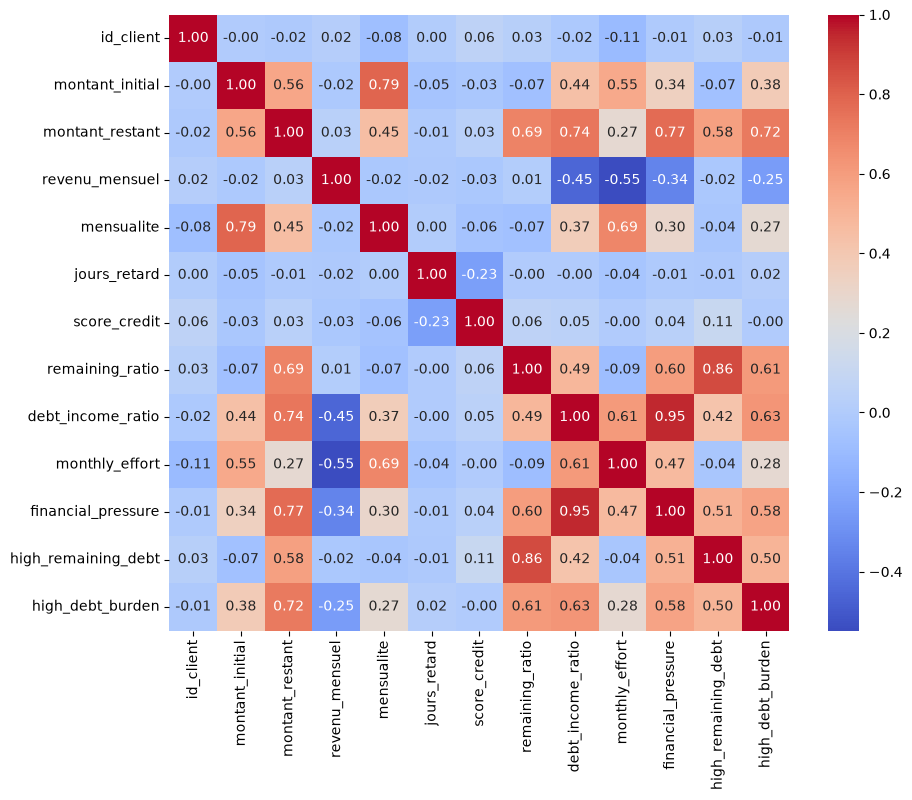

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))

sns.heatmap(

    debt_features.select_dtypes(include=np.number).corr(),

    annot=True,

    cmap="coolwarm",

    fmt=".2f"

)

plt.show()